# Experiment 07 — Real-World Robustness

## E4 & E5 — Noise and Missing Data Robustness

### 1. Mục tiêu

Đánh giá khả năng chống chịu (*robustness*) của DeepKoopFormer khi chất lượng dữ liệu chuỗi thời gian đầu vào bị suy giảm.

Thực nghiệm tập trung vào hai vấn đề thường gặp trong thực tế:

- **E4 — Noise Robustness:** Đánh giá ảnh hưởng của nhiễu Gaussian đến độ chính xác dự báo.
- **E5 — Missing Data Robustness:** Đánh giá ảnh hưởng của dữ liệu bị thiếu và các phương pháp xử lý giá trị thiếu.

So sánh hiệu năng giữa **PatchTST** và **KoopPatchTST_Full** trong các điều kiện đầu vào khác nhau.

### 2. Thiết kế thực nghiệm

**Datasets:**
- Electricity — 6 channels.
- CMIP6 Wind — 5 channels.

**Models:**
- PatchTST.
- KoopPatchTST_Full.

Sử dụng các mô hình đã huấn luyện trong E1 — Data Scaling với Train Ratio = 100%.

**E4 — Noise Robustness:**

- Thêm nhiễu Gaussian vào dữ liệu đầu vào Test.
- Noise Levels: 0%, 5%, 10%, 20%, 30%.
- Đánh giá lặp lại trên 5 random seeds.

**E5 — Missing Data Robustness:**

- Giả lập thiếu dữ liệu ngẫu nhiên ở các mức 0%, 5%, 10%, 20%, 30%.
- Xử lý giá trị thiếu bằng Mean Imputation và Forward Fill.
- Đánh giá lặp lại trên 5 random seeds.

Chỉ thay đổi dữ liệu đầu vào Test, giữ nguyên nhãn dự báo và trọng số mô hình.

**Training bổ sung: 0 — Inference Only.**

### 3. Chỉ số đánh giá

- Mean Squared Error (MSE).
- Mean Absolute Error (MAE).
- Relative MSE Degradation (%).
- Trung bình và độ lệch chuẩn giữa các lần đánh giá.

### 4. Quy trình thực hiện

1. Nạp các mô hình đã huấn luyện và dữ liệu Test.
2. Đánh giá trên dữ liệu gốc để xác lập baseline.
3. Thực hiện E4 với các mức nhiễu Gaussian.
4. Thực hiện E5 với các tỷ lệ dữ liệu thiếu và phương pháp imputation.
5. Tổng hợp kết quả và trực quan hóa.

### 5. Kết quả đầu ra

- `noise_metrics.csv` — Kết quả E4.
- `missing_metrics.csv` — Kết quả E5.
- Các biểu đồ so sánh MSE, MAE và mức suy giảm hiệu năng.
- Không huấn luyện lại mô hình và không thay đổi checkpoint.

### 6. Ý nghĩa

Hai thí nghiệm giúp đánh giá mức độ ổn định của khả năng dự báo khi dữ liệu đầu vào không hoàn hảo, qua đó cung cấp thêm bằng chứng về khả năng ứng dụng của DeepKoopFormer trong những điều kiện dữ liệu thực tế.

E4 & E5: ENVIRONMENT SETUP

In [1]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import torch

# 1. Reproducibility
SEED = 7

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# 2. Locate project root
PROJECT_ROOT = next(
    (
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (
            p / "experiments" / "05_ablation"
            / "02_ablation_model.ipynb"
        ).is_file()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Cannot locate project root")

# 3. Directories
EXPERIMENT_DIR = PROJECT_ROOT / "experiments"

ABLATION_DIR = EXPERIMENT_DIR / "05_ablation"
E1_DIR = (
    EXPERIMENT_DIR / "06_scalability"
    / "results" / "e1_data_scaling"
)

ROBUSTNESS_DIR = (
    EXPERIMENT_DIR / "07_real_world_robustness"
)

DATA_DIR = ABLATION_DIR / "data"
MODEL_NOTEBOOK = ABLATION_DIR / "02_ablation_model.ipynb"
MODEL_DIR = E1_DIR / "models"

RESULTS_DIR = ROBUSTNESS_DIR / "results" / "noise_missing"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# 4. Dataset configuration
DATASET_FILES = {
    "Electricity": "electricity_ablation.pt",
    "CMIP6 Wind": "cmip6_wind_ablation.pt"
}

MODEL_NAMES = [
    "PatchTST",
    "KoopPatchTST_Full"
]

# 5. Completed model files from E1 (100% Train)
MODEL_FILES = {
    ("Electricity", "PatchTST"):
        "electricity_patchtst_r100.pt",

    ("Electricity", "KoopPatchTST_Full"):
        "electricity_kooppatchtst_full_r100.pt",

    ("CMIP6 Wind", "PatchTST"):
        "cmip6_wind_patchtst_r100.pt",

    ("CMIP6 Wind", "KoopPatchTST_Full"):
        "cmip6_wind_kooppatchtst_full_r100.pt"
}

# 6. Robustness configuration
NOISE_LEVELS = [0.00, 0.05, 0.10, 0.20, 0.30]
MISSING_RATES = [0.00, 0.05, 0.10, 0.20, 0.30]

EVAL_SEEDS = [7, 17, 27, 37, 47]

IMPUTATION_METHODS = [
    "mean",
    "forward_fill"
]

SEQ_LEN = 120
HORIZON = 8

# 7. Validate required files
assert MODEL_NOTEBOOK.is_file()

for filename in DATASET_FILES.values():
    assert (DATA_DIR / filename).is_file(), filename

for filename in MODEL_FILES.values():
    assert (MODEL_DIR / filename).is_file(), filename

# 8. Summary
print("=== E4 & E5: REAL-WORLD ROBUSTNESS ===")

print("Project:", PROJECT_ROOT)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nDatasets:", list(DATASET_FILES))
print("Models:", MODEL_NAMES)
print("Completed E1 models:", len(MODEL_FILES))

print("\nNoise levels:", NOISE_LEVELS)
print("Missing rates:", MISSING_RATES)
print("Evaluation seeds:", EVAL_SEEDS)
print("Imputation methods:", IMPUTATION_METHODS)

print("\nSequence length:", SEQ_LEN)
print("Horizon:", HORIZON)

print("\nTraining required: NO")
print("Evaluation mode: INFERENCE ONLY")
print("Results directory:", RESULTS_DIR)

print("\nENVIRONMENT SETUP PASSED!")

=== E4 & E5: REAL-WORLD ROBUSTNESS ===
Project: c:\Users\Win 11 New\Desktop\pa gk
Device: cuda
GPU: Quadro T1000

Datasets: ['Electricity', 'CMIP6 Wind']
Models: ['PatchTST', 'KoopPatchTST_Full']
Completed E1 models: 4

Noise levels: [0.0, 0.05, 0.1, 0.2, 0.3]
Missing rates: [0.0, 0.05, 0.1, 0.2, 0.3]
Evaluation seeds: [7, 17, 27, 37, 47]
Imputation methods: ['mean', 'forward_fill']

Sequence length: 120
Horizon: 8

Training required: NO
Evaluation mode: INFERENCE ONLY
Results directory: c:\Users\Win 11 New\Desktop\pa gk\experiments\07_real_world_robustness\results\noise_missing

ENVIRONMENT SETUP PASSED!


LOAD DATASETS & TRAINED MODELS

In [ ]:
import sys
import hashlib

sys.path.insert(0, str(ABLATION_DIR))

import ast
import json
import math
import torch.nn as nn

MODEL_DEFINITIONS = {
    "_orth",
    "StrictStableKoopmanOperator",
    "LinearLatentPropagator",
    "SinCosPosEnc",
    "PatchEmbed1D",
    "PatchTST_Backbone",
    "PatchTSTBaseline",
    "PatchTST_UnconstrainedLatent",
    "Koopformer_PatchTST",
    "SimpleLSTMForecaster",
    "DLinearForecaster",
    "create_ablation_model",
}


def load_model_notebook(path):
    """Load model definitions without executing notebook cells."""

    with open(path, encoding="utf-8") as f:
        notebook = json.load(f)

    definitions = []
    found = set()

    for cell in notebook["cells"]:
        if cell["cell_type"] != "code":
            continue

        source = cell["source"]
        source = (
            "".join(source)
            if isinstance(source, list)
            else source
        )

        if not source.strip():
            continue

        tree = ast.parse(source)

        for node in tree.body:
            if isinstance(node, (ast.ClassDef, ast.FunctionDef)):
                if node.name in MODEL_DEFINITIONS:
                    if node.name in found:
                        raise ValueError(
                            f"Duplicate definition: {node.name}"
                        )
                    definitions.append(node)
                    found.add(node.name)

    missing = MODEL_DEFINITIONS - found
    if missing:
        raise RuntimeError(
            f"Missing model definitions: {sorted(missing)}"
        )

    namespace = {
        "__name__": __name__,
        "torch": torch,
        "nn": nn,
        "np": np,
        "math": math,
        "D_MODEL": 96,
        "D_LATENT": 96,
        "LSTM_HIDDEN_DIM": 96,
        "LSTM_NUM_LAYERS": 2,
        "LYAP_WEIGHT": 0.1,
        "RHO_MAX": 0.99,
        "MODEL_VARIANTS": [
            "DLinear",
            "LSTM",
            "PatchTST",
            "PatchTST+LinearLatent",
            "KoopPatchTST_NoLyap",
            "KoopPatchTST_Full",
        ],
    }

    module = ast.Module(
        body=definitions,
        type_ignores=[]
    )
    ast.fix_missing_locations(module)

    exec(
        compile(module, str(path), "exec"),
        namespace
    )

    return namespace

def safe_load(path):
    try:
        return torch.load(
            path,
            map_location="cpu",
            weights_only=True
        )
    except TypeError:
        return torch.load(
            path,
            map_location="cpu"
        )

# 1. Load model architecture from Ablation
model_definitions = load_model_notebook(MODEL_NOTEBOOK)

create_ablation_model = model_definitions[
    "create_ablation_model"
]

# 2. Load datasets
ROBUST_DATA = {}

for dataset_name, filename in DATASET_FILES.items():

    bundle = torch.load(
        DATA_DIR / filename,
        map_location="cpu",
        weights_only=True
    )

    train = bundle["train"].float()
    test = bundle["test"].float()
    channels = int(bundle["input_dim"])

    assert train.ndim == test.ndim == 2
    assert train.shape[1] == test.shape[1] == channels
    assert torch.isfinite(train).all()
    assert torch.isfinite(test).all()

    ROBUST_DATA[dataset_name] = {
        "train": train,
        "test": test,
        "channels": channels
    }

# 3. Load four trained models
ROBUST_MODELS = {}
rows = []

model_sha = hashlib.sha256(
    MODEL_NOTEBOOK.read_bytes()
).hexdigest()

for (dataset_name, model_name), filename in MODEL_FILES.items():

    artifact = safe_load(MODEL_DIR / filename)
    config = artifact["config"]

    channels = ROBUST_DATA[dataset_name]["channels"]

    # Verify checkpoint configuration
    assert config["dataset"] == dataset_name
    assert config["model"] == model_name
    assert config["ratio"] == 1.0
    assert config["patch_len"] == SEQ_LEN
    assert config["horizon"] == HORIZON
    assert config["epochs"] == 4000
    assert config["channels"] == channels
    assert config["model_sha256"] == model_sha

    # Initialize the same architecture
    model, koop_attr, lyap_weight = (
        create_ablation_model(
            model_name=model_name,
            input_dim=channels,
            patch_len=SEQ_LEN,
            horizon=HORIZON
        )
    )

    # Restore trained weights
    model.load_state_dict(
        artifact["model_state_dict"],
        strict=True
    )

    model = model.to(DEVICE)
    model.eval()

    # Restore Min-Max transformation information
    scaler_scale = np.asarray(
        artifact["scaler"]["scale"],
        dtype=np.float64
    )

    scaler_min = np.asarray(
        artifact["scaler"]["min"],
        dtype=np.float64
    )

    assert scaler_scale.shape == (channels,)
    assert scaler_min.shape == (channels,)

    # Validate forward pass
    dummy_x = ROBUST_DATA[dataset_name]["test"][
        :SEQ_LEN
    ].unsqueeze(0).to(DEVICE)

    with torch.inference_mode():
        prediction = model(dummy_x)

    assert prediction.shape == (1, channels * HORIZON)
    assert torch.isfinite(prediction).all()

    # Store in memory for E4/E5
    ROBUST_MODELS[(dataset_name, model_name)] = {
        "model": model,
        "scaler_scale": scaler_scale,
        "scaler_min": scaler_min,
        "parameters": sum(
            p.numel() for p in model.parameters()
        )
    }

    rows.append({
        "Dataset": dataset_name,
        "Model": model_name,
        "Channels": channels,
        "Parameters": sum(
            p.numel() for p in model.parameters()
        ),
        "Output Shape": str(tuple(prediction.shape)),
        "Status": "PASSED"
    })

# 4. Summary
model_df = pd.DataFrame(rows)

print("=== E4 & E5 MODEL LOADING ===")
display(model_df)

assert len(ROBUST_MODELS) == 4
assert (model_df["Status"] == "PASSED").all()

print("\nDatasets loaded:", len(ROBUST_DATA))
print("Trained models loaded:", len(ROBUST_MODELS))
print("All models in evaluation mode.")
print("No training performed.")
print("\nMODEL LOADING PASSED!")


c:\Users\Win 11 New\Desktop\pa gk\.venv\lib\site-packages\torch\_utils.py:776: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


=== E4 & E5 MODEL LOADING ===


,Dataset,Model,Channels,Parameters,Output Shape,Status
0,Electricity,PatchTST,6,242736,"(1, 48)",PASSED
1,Electricity,KoopPatchTST_Full,6,261264,"(1, 48)",PASSED
2,CMIP6 Wind,PatchTST,5,230440,"(1, 40)",PASSED
3,CMIP6 Wind,KoopPatchTST_Full,5,248968,"(1, 40)",PASSED



Datasets loaded: 2
Trained models loaded: 4
All models in evaluation mode.
No training performed.

MODEL LOADING PASSED!


TEST WINDOWS & CLEAN BASELINE

In [ ]:
@torch.no_grad()
def predict_cpu_tensor(model, X, device, batch_size):
    model.eval()
    predictions = []

    with torch.inference_mode():
        for start in range(0, len(X), batch_size):
            batch = X[start:start + batch_size].to(device)

            predictions.append(
                model(batch).detach().cpu().clone()
            )

    return torch.cat(predictions, dim=0)

# 1. Sliding windows (same as Ablation and E1)
def create_windows(data, seq_len, horizon):

    X, Y = [], []

    for i in range(len(data) - seq_len - horizon):

        X.append(data[i:i + seq_len])

        Y.append(
            data[i + seq_len:i + seq_len + horizon]
            .T.reshape(-1)
        )

    return torch.stack(X), torch.stack(Y)


# 2. Evaluation function (original and scaled units)
def evaluate_model(model, X, Y, scaler_scale, channels):

    prediction = predict_cpu_tensor(
        model, X, DEVICE, 256
    ).numpy().astype(np.float64)

    target = Y.numpy().astype(np.float64)

    # Scaled error
    scaled_diff = prediction - target

    # Original-unit error
    # Feature-major output: (N, channels, horizon)
    diff_3d = scaled_diff.reshape(
        -1, channels, HORIZON
    )

    raw_diff = diff_3d / scaler_scale.reshape(
        1, channels, 1
    )

    return {
        "MSE": float(np.mean(raw_diff ** 2)),
        "MAE": float(np.mean(np.abs(raw_diff))),
        "MSE_Scaled": float(np.mean(scaled_diff ** 2)),
        "MAE_Scaled": float(np.mean(np.abs(scaled_diff)))
    }


# 3. Prepare common Test windows
ROBUST_WINDOWS = {}

for dataset_name, data in ROBUST_DATA.items():

    X_test, Y_test = create_windows(
        data["test"], SEQ_LEN, HORIZON
    )

    assert X_test.shape[1:] == (
        SEQ_LEN, data["channels"]
    )

    assert Y_test.shape[1] == (
        data["channels"] * HORIZON
    )

    ROBUST_WINDOWS[dataset_name] = {
        "X_test": X_test,
        "Y_test": Y_test,
        "train_mean": data["train"].mean(dim=0).numpy(),
        "train_std": data["train"].std(
            dim=0, unbiased=False
        ).numpy()
    }


# 4. Evaluate all four models on clean Test data
CLEAN_BASELINE = {}
rows = []

for (dataset_name, model_name), info in ROBUST_MODELS.items():

    windows = ROBUST_WINDOWS[dataset_name]

    result = evaluate_model(
        model=info["model"],
        X=windows["X_test"],
        Y=windows["Y_test"],
        scaler_scale=info["scaler_scale"],
        channels=ROBUST_DATA[dataset_name]["channels"]
    )

    CLEAN_BASELINE[(dataset_name, model_name)] = result

    # 5. Compare with saved E1 test metrics
    filename = MODEL_FILES[(dataset_name, model_name)]
    artifact = safe_load(MODEL_DIR / filename)

    expected = artifact["metrics"]["Test"]

    for metric in ["MSE", "MAE", "MSE_Scaled", "MAE_Scaled"]:

        np.testing.assert_allclose(
            result[metric],
            expected[metric],
            rtol=1e-4,
            atol=1e-5
        )

    rows.append({
        "Dataset": dataset_name,
        "Model": model_name,
        "Test Windows": len(windows["X_test"]),
        **result,
        "Status": "MATCHED"
    })


# 6. Save clean baseline
baseline_df = pd.DataFrame(rows)

baseline_df.to_csv(
    RESULTS_DIR / "clean_baseline.csv",
    index=False
)

print("=== E4 & E5 CLEAN BASELINE ===")
display(baseline_df)

assert len(baseline_df) == 4
assert (baseline_df["Status"] == "MATCHED").all()

print("\nAll four models matched E1 Test metrics.")
print("Clean baseline saved.")
print("CLEAN BASELINE PASSED!")


=== E4 & E5 CLEAN BASELINE ===


,Dataset,Model,Test Windows,MSE,MAE,MSE_Scaled,MAE_Scaled,Status
0,Electricity,PatchTST,572,243964.529580,246.689988,0.017094,0.084982,MATCHED
1,Electricity,KoopPatchTST_Full,572,304091.761049,272.589563,0.020158,0.093146,MATCHED
2,CMIP6 Wind,PatchTST,456,8.344484,2.084603,0.039099,0.149085,MATCHED
3,CMIP6 Wind,KoopPatchTST_Full,456,8.275643,2.112195,0.039616,0.151979,MATCHED



All four models matched E1 Test metrics.
Clean baseline saved.
CLEAN BASELINE PASSED!


E4: GAUSSIAN NOISE ROBUSTNESS

In [4]:
import time

NOISE_CSV = RESULTS_DIR / "noise_metrics.csv"

COLUMNS = [
    "Dataset", "Model", "Noise_Level", "Seed",
    "MSE", "MAE", "MSE_Scaled", "MAE_Scaled",
    "MSE_Degradation_Pct", "MAE_Degradation_Pct"
]

# 1. Load existing results for safe resume
if NOISE_CSV.exists():
    noise_df = pd.read_csv(NOISE_CSV)

    assert set(COLUMNS).issubset(noise_df.columns)

    noise_df = noise_df[COLUMNS].copy()

else:
    noise_df = pd.DataFrame(columns=COLUMNS)

KEY_COLS = ["Dataset", "Model", "Noise_Level", "Seed"]

assert not noise_df.duplicated(KEY_COLS).any(), (
    "Duplicate E4 evaluations detected"
)


def is_completed(dataset, model, level, seed):
    mask = (
        (noise_df["Dataset"] == dataset)
        & (noise_df["Model"] == model)
        & np.isclose(
            noise_df["Noise_Level"].astype(float),
            level
        )
        & (noise_df["Seed"] == seed)
    )
    return bool(mask.any())


def save_noise_results():
    # Atomic CSV replacement
    temp_path = NOISE_CSV.with_suffix(".tmp")
    noise_df.to_csv(temp_path, index=False)
    temp_path.replace(NOISE_CSV)


# 2. Run Gaussian noise evaluation
total_jobs = (
    len(DATASET_FILES)
    * len(MODEL_NAMES)
    * len(NOISE_LEVELS)
    * len(EVAL_SEEDS)
)

print("=== E4 — GAUSSIAN NOISE ROBUSTNESS ===")
print("Total evaluations:", total_jobs)
print("Previously completed:", len(noise_df))
print("Training: NO")
print()

start_time = time.perf_counter()

for dataset_idx, dataset_name in enumerate(DATASET_FILES):

    windows = ROBUST_WINDOWS[dataset_name]

    X_clean = windows["X_test"]
    Y_test = windows["Y_test"]

    channels = ROBUST_DATA[dataset_name]["channels"]

    # Per-channel standard deviation from Train
    train_std = torch.as_tensor(
        windows["train_std"],
        dtype=X_clean.dtype
    ).reshape(1, 1, channels)

    print(f"\nDATASET: {dataset_name}")
    print("Test windows:", len(X_clean))

    for seed in EVAL_SEEDS:

        # Fixed noise realization for each dataset/seed.
        # Reuse it across levels and models.
        generator = torch.Generator(device="cpu")
        generator.manual_seed(
            int(seed + 10000 * dataset_idx)
        )

        epsilon = torch.randn(
            X_clean.shape,
            generator=generator,
            dtype=X_clean.dtype
        )

        for level in NOISE_LEVELS:

            level = float(level)

            # Gaussian noise is proportional to Train std
            X_noisy = (
                X_clean + level * train_std * epsilon
            ) if level > 0 else X_clean

            assert torch.isfinite(X_noisy).all()

            for model_name in MODEL_NAMES:

                if is_completed(
                    dataset_name, model_name,
                    level, seed
                ):
                    continue

                key = (dataset_name, model_name)
                info = ROBUST_MODELS[key]
                clean = CLEAN_BASELINE[key]

                # At zero noise, use verified clean baseline
                if level == 0:
                    result = dict(clean)

                else:
                    result = evaluate_model(
                        model=info["model"],
                        X=X_noisy,
                        Y=Y_test,
                        scaler_scale=info["scaler_scale"],
                        channels=channels
                    )

                mse_degradation = (
                    (result["MSE"] - clean["MSE"])
                    / clean["MSE"] * 100.0
                )

                mae_degradation = (
                    (result["MAE"] - clean["MAE"])
                    / clean["MAE"] * 100.0
                )

                new_row = {
                    "Dataset": dataset_name,
                    "Model": model_name,
                    "Noise_Level": level,
                    "Seed": seed,
                    **result,
                    "MSE_Degradation_Pct":
                        mse_degradation,
                    "MAE_Degradation_Pct":
                        mae_degradation
                }

                noise_df = pd.concat(
                    [
                        noise_df,
                        pd.DataFrame([new_row])
                    ],
                    ignore_index=True
                )

                # Save after every evaluation
                save_noise_results()

            print(
                f"  Seed={seed:2d} | "
                f"Noise={level:.0%} | "
                f"Completed={len(noise_df)}/{total_jobs}"
            )

    print(f"FINISHED DATASET: {dataset_name}")


# 3. Final validation
noise_df = pd.read_csv(NOISE_CSV)

assert len(noise_df) == total_jobs, (
    f"Incomplete E4: {len(noise_df)}/{total_jobs}"
)

assert not noise_df.duplicated(KEY_COLS).any()

assert np.isfinite(
    noise_df[
        [
            "MSE", "MAE",
            "MSE_Scaled", "MAE_Scaled",
            "MSE_Degradation_Pct",
            "MAE_Degradation_Pct"
        ]
    ].to_numpy(dtype=float)
).all()

zero_noise = noise_df[
    np.isclose(noise_df["Noise_Level"], 0.0)
]

np.testing.assert_allclose(
    zero_noise["MSE_Degradation_Pct"],
    0.0,
    atol=1e-8
)

np.testing.assert_allclose(
    zero_noise["MAE_Degradation_Pct"],
    0.0,
    atol=1e-8
)

# 4. Summary by model and noise level
summary = (
    noise_df.groupby(
        ["Dataset", "Model", "Noise_Level"],
        as_index=False
    )
    .agg(
        MSE_Mean=("MSE", "mean"),
        MSE_Std=("MSE", "std"),
        MAE_Mean=("MAE", "mean"),
        MAE_Std=("MAE", "std"),
        MSE_Degradation_Mean=(
            "MSE_Degradation_Pct", "mean"
        )
    )
    .sort_values(
        ["Dataset", "Model", "Noise_Level"]
    )
)

summary.to_csv(
    RESULTS_DIR / "noise_summary.csv",
    index=False
)

print("\n=== E4 SUMMARY ===")
display(summary.round(6))

print("\nEvaluations:", len(noise_df), "/", total_jobs)
print("Summary rows:", len(summary))
print(
    "Elapsed:",
    round(time.perf_counter() - start_time, 1),
    "seconds"
)

print("\nSaved:", NOISE_CSV)
print("Saved:", RESULTS_DIR / "noise_summary.csv")
print("\nE4 GAUSSIAN NOISE ROBUSTNESS PASSED!")


=== E4 — GAUSSIAN NOISE ROBUSTNESS ===
Total evaluations: 100
Previously completed: 0
Training: NO


DATASET: Electricity
Test windows: 572
  Seed= 7 | Noise=0% | Completed=2/100
  Seed= 7 | Noise=5% | Completed=4/100


C:\Users\Win 11 New\AppData\Local\Temp\ipykernel_14468\3252681745.py:156: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  noise_df = pd.concat(


  Seed= 7 | Noise=10% | Completed=6/100
  Seed= 7 | Noise=20% | Completed=8/100
  Seed= 7 | Noise=30% | Completed=10/100
  Seed=17 | Noise=0% | Completed=12/100
  Seed=17 | Noise=5% | Completed=14/100
  Seed=17 | Noise=10% | Completed=16/100
  Seed=17 | Noise=20% | Completed=18/100
  Seed=17 | Noise=30% | Completed=20/100
  Seed=27 | Noise=0% | Completed=22/100
  Seed=27 | Noise=5% | Completed=24/100
  Seed=27 | Noise=10% | Completed=26/100
  Seed=27 | Noise=20% | Completed=28/100
  Seed=27 | Noise=30% | Completed=30/100
  Seed=37 | Noise=0% | Completed=32/100
  Seed=37 | Noise=5% | Completed=34/100
  Seed=37 | Noise=10% | Completed=36/100
  Seed=37 | Noise=20% | Completed=38/100
  Seed=37 | Noise=30% | Completed=40/100
  Seed=47 | Noise=0% | Completed=42/100
  Seed=47 | Noise=5% | Completed=44/100
  Seed=47 | Noise=10% | Completed=46/100
  Seed=47 | Noise=20% | Completed=48/100
  Seed=47 | Noise=30% | Completed=50/100
FINISHED DATASET: Electricity

DATASET: CMIP6 Wind
Test windows: 45

,Dataset,Model,Noise_Level,MSE_Mean,MSE_Std,MAE_Mean,MAE_Std,MSE_Degradation_Mean
0,CMIP6 Wind,KoopPatchTST_Full,0.00,8.275643,0.000000,2.112195,0.000000,0.000000
1,CMIP6 Wind,KoopPatchTST_Full,0.05,8.285928,0.004265,2.112835,0.000926,0.124278
2,CMIP6 Wind,KoopPatchTST_Full,0.10,8.307252,0.007944,2.115255,0.001859,0.381952
3,CMIP6 Wind,KoopPatchTST_Full,0.20,8.378038,0.015090,2.124448,0.004041,1.237312
4,CMIP6 Wind,KoopPatchTST_Full,0.30,8.481498,0.023624,2.138599,0.006939,2.487483
5,CMIP6 Wind,PatchTST,0.00,8.344484,0.000000,2.084603,0.000000,0.000000
6,CMIP6 Wind,PatchTST,0.05,8.344316,0.003590,2.084456,0.001019,-0.002017
7,CMIP6 Wind,PatchTST,0.10,8.356897,0.007279,2.086482,0.002209,0.148753
8,CMIP6 Wind,PatchTST,0.20,8.416129,0.013394,2.096630,0.004584,0.858588
9,CMIP6 Wind,PatchTST,0.30,8.521335,0.023384,2.114151,0.006813,2.119376



Evaluations: 100 / 100
Summary rows: 20
Elapsed: 2.1 seconds

Saved: c:\Users\Win 11 New\Desktop\pa gk\experiments\07_real_world_robustness\results\noise_missing\noise_metrics.csv
Saved: c:\Users\Win 11 New\Desktop\pa gk\experiments\07_real_world_robustness\results\noise_missing\noise_summary.csv

E4 GAUSSIAN NOISE ROBUSTNESS PASSED!


MISSING DATA ROBUSTNESS

In [5]:
import time

MISSING_CSV = RESULTS_DIR / "missing_metrics.csv"

MISSING_COLUMNS = [
    "Dataset", "Model", "Missing_Rate",
    "Imputation", "Seed", "Actual_Missing_Rate",
    "MSE", "MAE", "MSE_Scaled", "MAE_Scaled",
    "MSE_Degradation_Pct", "MAE_Degradation_Pct"
]

KEY_COLS = [
    "Dataset", "Model", "Missing_Rate",
    "Imputation", "Seed"
]

# 1. Resume existing evaluations
if MISSING_CSV.exists():
    missing_df = pd.read_csv(MISSING_CSV)
    assert set(MISSING_COLUMNS).issubset(missing_df.columns)
    missing_df = missing_df[MISSING_COLUMNS].copy()
else:
    missing_df = pd.DataFrame(columns=MISSING_COLUMNS)

assert not missing_df.duplicated(KEY_COLS).any()


def missing_completed(dataset, model, rate, method, seed):
    mask = (
        (missing_df["Dataset"] == dataset)
        & (missing_df["Model"] == model)
        & np.isclose(
            missing_df["Missing_Rate"].astype(float),
            rate
        )
        & (missing_df["Imputation"] == method)
        & (missing_df["Seed"] == seed)
    )
    return bool(mask.any())


def save_missing_results():
    temp = MISSING_CSV.with_suffix(".tmp")
    missing_df.to_csv(temp, index=False)
    temp.replace(MISSING_CSV)


# 2. Mean imputation
def mean_imputation(X, missing_mask, train_mean):

    mean = torch.as_tensor(
        train_mean,
        dtype=X.dtype,
        device=X.device
    ).reshape(1, 1, -1)

    return torch.where(missing_mask, mean, X)


# 3. Forward fill without future leakage
def forward_fill_imputation(X, missing_mask, train_mean):

    N, L, C = X.shape

    mean = torch.as_tensor(
        train_mean,
        dtype=X.dtype,
        device=X.device
    ).reshape(1, 1, C)

    # Index of each timestamp
    time_idx = torch.arange(
        L, device=X.device
    ).reshape(1, L, 1).expand(N, L, C)

    # Missing positions cannot serve as observations
    valid_idx = time_idx.masked_fill(
        missing_mask, -1
    )

    # Most recent valid index at or before each timestamp
    last_valid_idx = torch.cummax(
        valid_idx, dim=1
    ).values

    gather_idx = last_valid_idx.clamp(min=0)

    previous_values = torch.gather(
        X, dim=1, index=gather_idx
    )

    # Leading missing values use Train mean
    result = torch.where(
        last_valid_idx >= 0,
        previous_values,
        mean
    )

    return result


IMPUTATION_FUNCTIONS = {
    "mean": mean_imputation,
    "forward_fill": forward_fill_imputation
}


# 4. Missing data evaluation
total_jobs = (
    len(DATASET_FILES)
    * len(MODEL_NAMES)
    * len(MISSING_RATES)
    * len(IMPUTATION_METHODS)
    * len(EVAL_SEEDS)
)

print("=== E5 — MISSING DATA ROBUSTNESS ===")
print("Total evaluations:", total_jobs)
print("Previously completed:", len(missing_df))
print("Training: NO")

start_time = time.perf_counter()

for dataset_idx, dataset_name in enumerate(DATASET_FILES):

    windows = ROBUST_WINDOWS[dataset_name]

    X_clean = windows["X_test"]
    Y_test = windows["Y_test"]
    train_mean = windows["train_mean"]

    channels = ROBUST_DATA[dataset_name]["channels"]

    print(f"\nDATASET: {dataset_name}")
    print("Test windows:", len(X_clean))

    for seed in EVAL_SEEDS:

        # Reproducible random mask source.
        # Same realization for both models and methods.
        generator = torch.Generator(device="cpu")
        generator.manual_seed(
            int(seed + 20000 * dataset_idx)
        )

        random_values = torch.rand(
            X_clean.shape,
            generator=generator,
            dtype=X_clean.dtype
        )

        for rate in MISSING_RATES:

            rate = float(rate)

            # MCAR: random missing entries
            missing_mask = random_values < rate

            actual_rate = float(
                missing_mask.float().mean().item()
            )

            for method in IMPUTATION_METHODS:

                # Prepare corrupted input once,
                # reuse for both models
                if rate == 0:
                    X_imputed = X_clean
                else:
                    X_imputed = IMPUTATION_FUNCTIONS[method](
                        X_clean,
                        missing_mask,
                        train_mean
                    )

                assert X_imputed.shape == X_clean.shape
                assert torch.isfinite(X_imputed).all()

                # Unmasked values must stay unchanged
                if rate > 0:
                    assert torch.equal(
                        X_imputed[~missing_mask],
                        X_clean[~missing_mask]
                    )

                for model_name in MODEL_NAMES:

                    if missing_completed(
                        dataset_name, model_name,
                        rate, method, seed
                    ):
                        continue

                    key = (dataset_name, model_name)

                    info = ROBUST_MODELS[key]
                    clean = CLEAN_BASELINE[key]

                    # Zero missing = verified clean baseline
                    if rate == 0:
                        result = dict(clean)

                    else:
                        result = evaluate_model(
                            model=info["model"],
                            X=X_imputed,
                            Y=Y_test,
                            scaler_scale=info["scaler_scale"],
                            channels=channels
                        )

                    mse_degradation = (
                        (result["MSE"] - clean["MSE"])
                        / clean["MSE"] * 100.0
                    )

                    mae_degradation = (
                        (result["MAE"] - clean["MAE"])
                        / clean["MAE"] * 100.0
                    )

                    new_row = {
                        "Dataset": dataset_name,
                        "Model": model_name,
                        "Missing_Rate": rate,
                        "Imputation": method,
                        "Seed": seed,
                        "Actual_Missing_Rate": actual_rate,
                        **result,
                        "MSE_Degradation_Pct":
                            mse_degradation,
                        "MAE_Degradation_Pct":
                            mae_degradation
                    }

                    missing_df = pd.concat(
                        [
                            missing_df,
                            pd.DataFrame([new_row])
                        ],
                        ignore_index=True
                    )

                    # Save each completed evaluation
                    save_missing_results()

            print(
                f"  Seed={seed:2d} | "
                f"Missing={rate:.0%} | "
                f"Actual={actual_rate:.2%} | "
                f"Completed={len(missing_df)}/{total_jobs}"
            )

    print(f"FINISHED DATASET: {dataset_name}")


# 5. Validate final results
missing_df = pd.read_csv(MISSING_CSV)

assert len(missing_df) == total_jobs, (
    f"Incomplete E5: {len(missing_df)}/{total_jobs}"
)

assert not missing_df.duplicated(KEY_COLS).any()

numeric_cols = [
    "Actual_Missing_Rate",
    "MSE", "MAE", "MSE_Scaled", "MAE_Scaled",
    "MSE_Degradation_Pct", "MAE_Degradation_Pct"
]

assert np.isfinite(
    missing_df[numeric_cols].to_numpy(dtype=float)
).all()

# Every configuration has all 5 seeds
counts = missing_df.groupby(
    ["Dataset", "Model", "Missing_Rate", "Imputation"]
).size()

assert len(counts) == 40
assert (counts == len(EVAL_SEEDS)).all()

# Clean inputs must match baseline
zero_missing = missing_df[
    np.isclose(missing_df["Missing_Rate"], 0.0)
]

np.testing.assert_allclose(
    zero_missing["MSE_Degradation_Pct"],
    0.0,
    atol=1e-8
)

np.testing.assert_allclose(
    zero_missing["MAE_Degradation_Pct"],
    0.0,
    atol=1e-8
)


# 6. Aggregate results
missing_summary = (
    missing_df.groupby(
        [
            "Dataset", "Model",
            "Missing_Rate", "Imputation"
        ],
        as_index=False
    )
    .agg(
        MSE_Mean=("MSE", "mean"),
        MSE_Std=("MSE", "std"),
        MAE_Mean=("MAE", "mean"),
        MAE_Std=("MAE", "std"),
        MSE_Degradation_Mean=(
            "MSE_Degradation_Pct", "mean"
        ),
        Actual_Missing_Rate_Mean=(
            "Actual_Missing_Rate", "mean"
        )
    )
    .sort_values(
        [
            "Dataset", "Model",
            "Imputation", "Missing_Rate"
        ]
    )
)

missing_summary.to_csv(
    RESULTS_DIR / "missing_summary.csv",
    index=False
)

print("\n=== E5 SUMMARY ===")
display(missing_summary.round(6))

print("\nEvaluations:", len(missing_df), "/", total_jobs)
print("Summary rows:", len(missing_summary))

print(
    "Elapsed:",
    round(time.perf_counter() - start_time, 1),
    "seconds"
)

print("\nSaved:", MISSING_CSV)
print("Saved:", RESULTS_DIR / "missing_summary.csv")

print("\nE5 MISSING DATA ROBUSTNESS PASSED!")


=== E5 — MISSING DATA ROBUSTNESS ===
Total evaluations: 200
Previously completed: 0
Training: NO

DATASET: Electricity
Test windows: 572
  Seed= 7 | Missing=0% | Actual=0.00% | Completed=4/200


C:\Users\Win 11 New\AppData\Local\Temp\ipykernel_14468\1052144573.py:236: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  missing_df = pd.concat(


  Seed= 7 | Missing=5% | Actual=4.96% | Completed=8/200
  Seed= 7 | Missing=10% | Actual=9.91% | Completed=12/200
  Seed= 7 | Missing=20% | Actual=19.90% | Completed=16/200
  Seed= 7 | Missing=30% | Actual=29.93% | Completed=20/200
  Seed=17 | Missing=0% | Actual=0.00% | Completed=24/200
  Seed=17 | Missing=5% | Actual=4.94% | Completed=28/200
  Seed=17 | Missing=10% | Actual=9.94% | Completed=32/200
  Seed=17 | Missing=20% | Actual=19.95% | Completed=36/200
  Seed=17 | Missing=30% | Actual=29.92% | Completed=40/200
  Seed=27 | Missing=0% | Actual=0.00% | Completed=44/200
  Seed=27 | Missing=5% | Actual=5.02% | Completed=48/200
  Seed=27 | Missing=10% | Actual=10.09% | Completed=52/200
  Seed=27 | Missing=20% | Actual=20.06% | Completed=56/200
  Seed=27 | Missing=30% | Actual=30.01% | Completed=60/200
  Seed=37 | Missing=0% | Actual=0.00% | Completed=64/200
  Seed=37 | Missing=5% | Actual=4.98% | Completed=68/200
  Seed=37 | Missing=10% | Actual=9.96% | Completed=72/200
  Seed=37 | Mis

,Dataset,Model,Missing_Rate,Imputation,MSE_Mean,MSE_Std,MAE_Mean,MAE_Std,MSE_Degradation_Mean,Actual_Missing_Rate_Mean
0,CMIP6 Wind,KoopPatchTST_Full,0.00,forward_fill,8.275643,0.000000,2.112195,0.000000,0.000000,0.000000
2,CMIP6 Wind,KoopPatchTST_Full,0.05,forward_fill,8.318856,0.024029,2.118217,0.003822,0.522168,0.050210
4,CMIP6 Wind,KoopPatchTST_Full,0.10,forward_fill,8.360847,0.049554,2.125674,0.007016,1.029577,0.100107
6,CMIP6 Wind,KoopPatchTST_Full,0.20,forward_fill,8.521132,0.078495,2.147864,0.010743,2.966412,0.199664
8,CMIP6 Wind,KoopPatchTST_Full,0.30,forward_fill,8.626775,0.085939,2.163359,0.014578,4.242955,0.299727
1,CMIP6 Wind,KoopPatchTST_Full,0.00,mean,8.275643,0.000000,2.112195,0.000000,0.000000,0.000000
3,CMIP6 Wind,KoopPatchTST_Full,0.05,mean,8.163768,0.079323,2.099583,0.010402,-1.351860,0.050210
5,CMIP6 Wind,KoopPatchTST_Full,0.10,mean,8.117129,0.060064,2.096986,0.009156,-1.915421,0.100107
7,CMIP6 Wind,KoopPatchTST_Full,0.20,mean,7.977738,0.051413,2.078685,0.006373,-3.599776,0.199664
9,CMIP6 Wind,KoopPatchTST_Full,0.30,mean,7.807218,0.037552,2.058082,0.010579,-5.660285,0.299727



Evaluations: 200 / 200
Summary rows: 40
Elapsed: 5.5 seconds

Saved: c:\Users\Win 11 New\Desktop\pa gk\experiments\07_real_world_robustness\results\noise_missing\missing_metrics.csv
Saved: c:\Users\Win 11 New\Desktop\pa gk\experiments\07_real_world_robustness\results\noise_missing\missing_summary.csv

E5 MISSING DATA ROBUSTNESS PASSED!


E4 & E5: VISUALIZATION

=== E4 & E5 VISUALIZATION ===

DATASET: Electricity


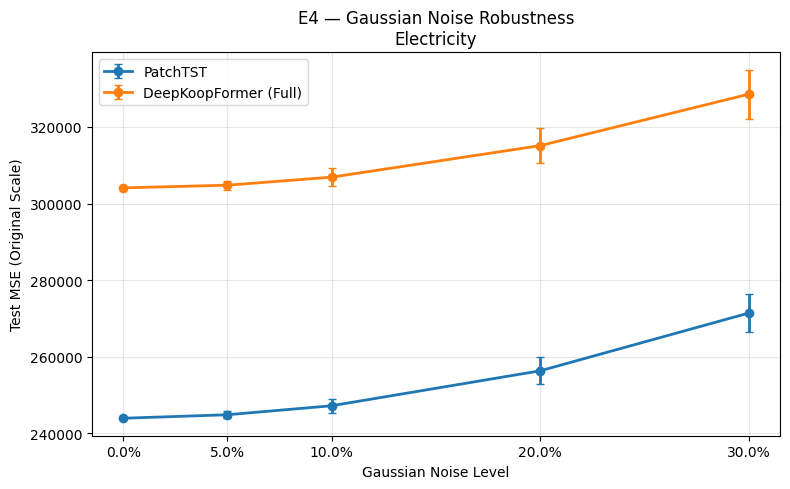

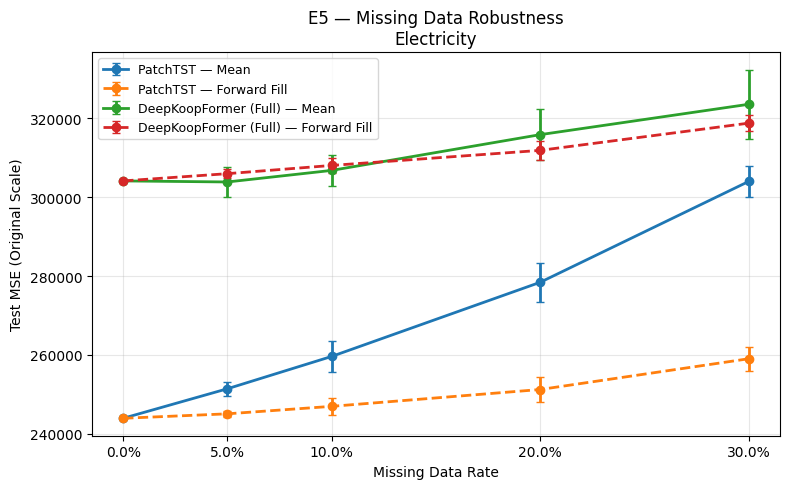

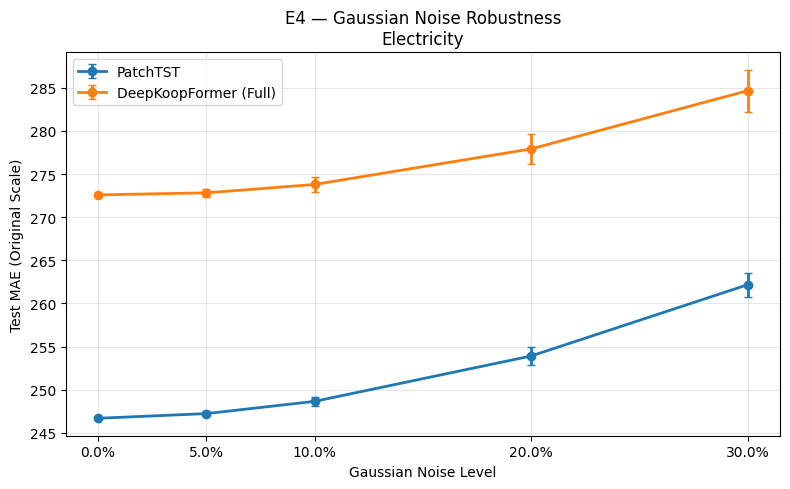

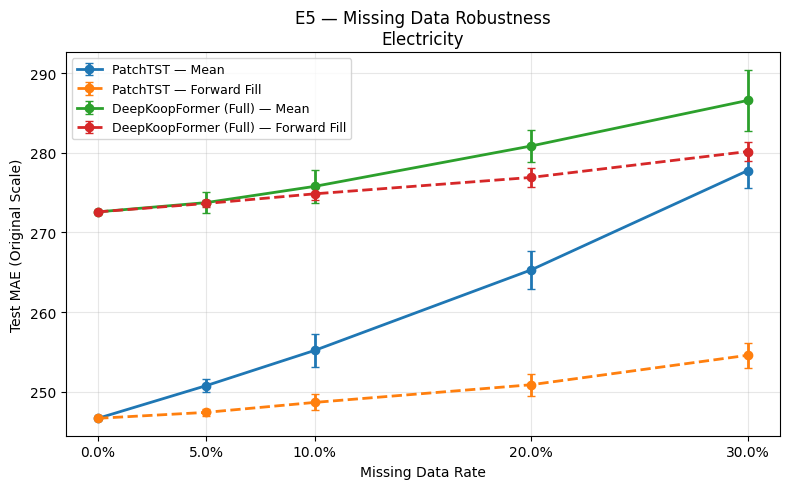

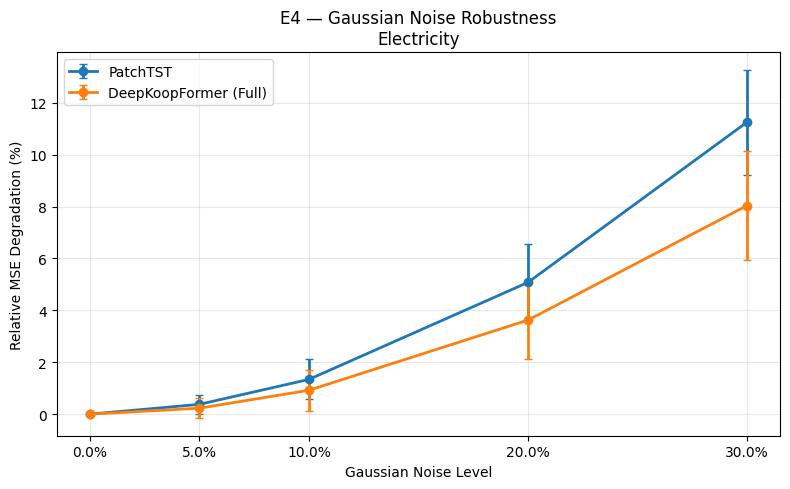

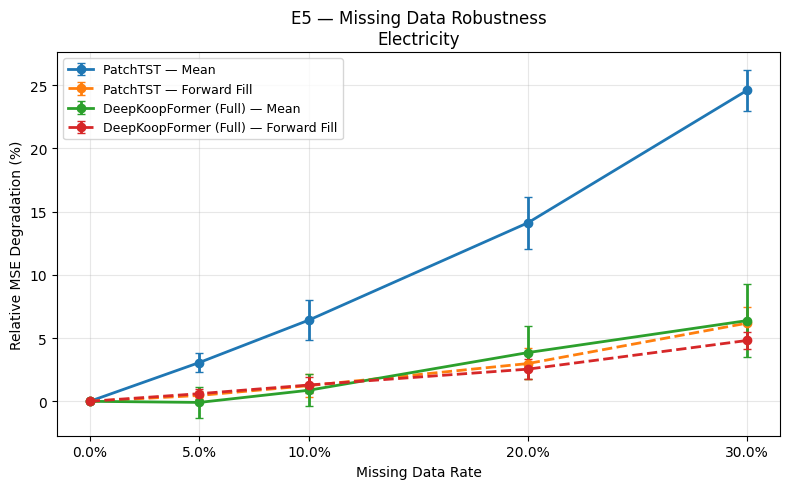

Saved 6 figures for Electricity

DATASET: CMIP6 Wind


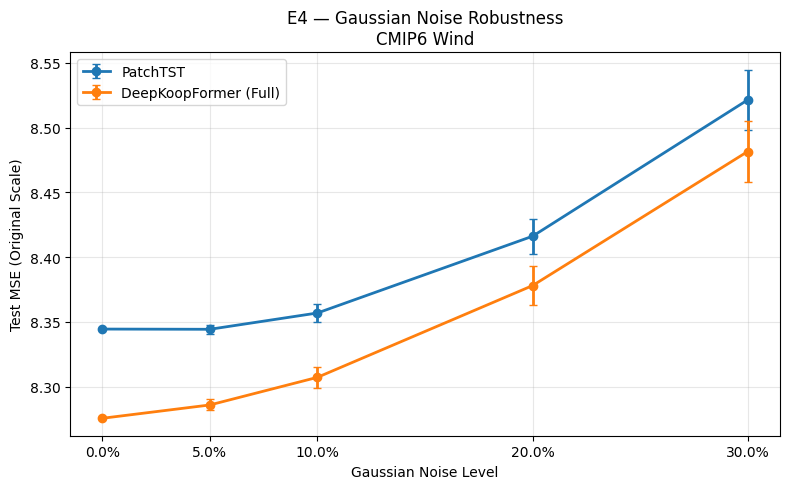

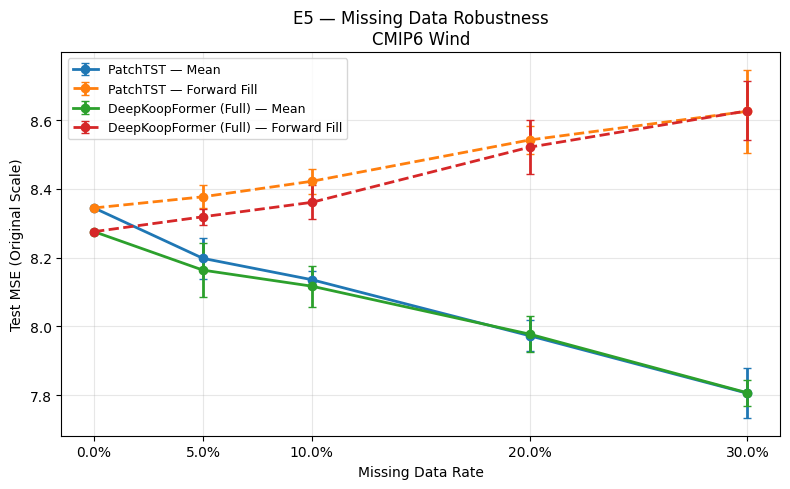

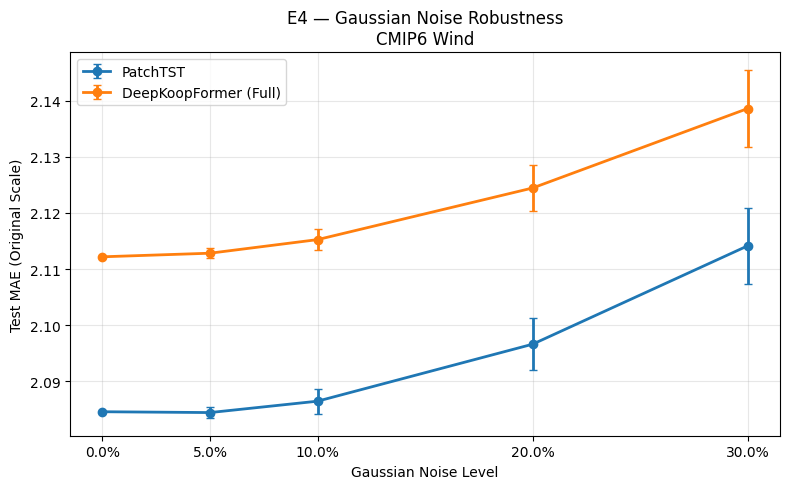

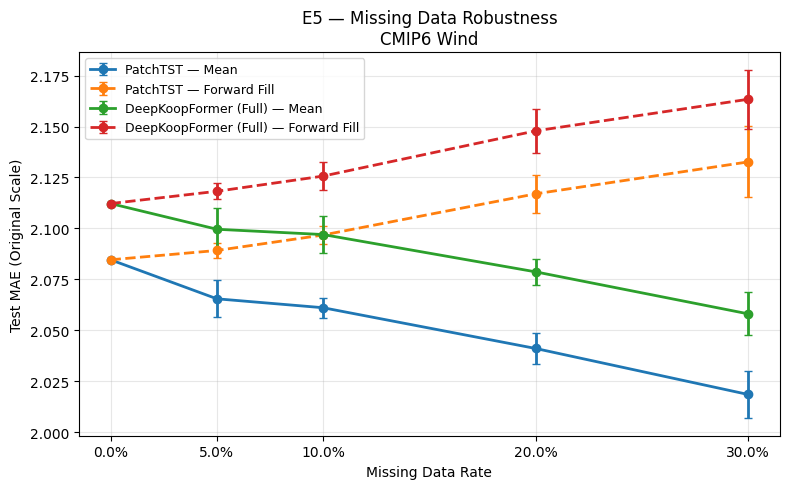

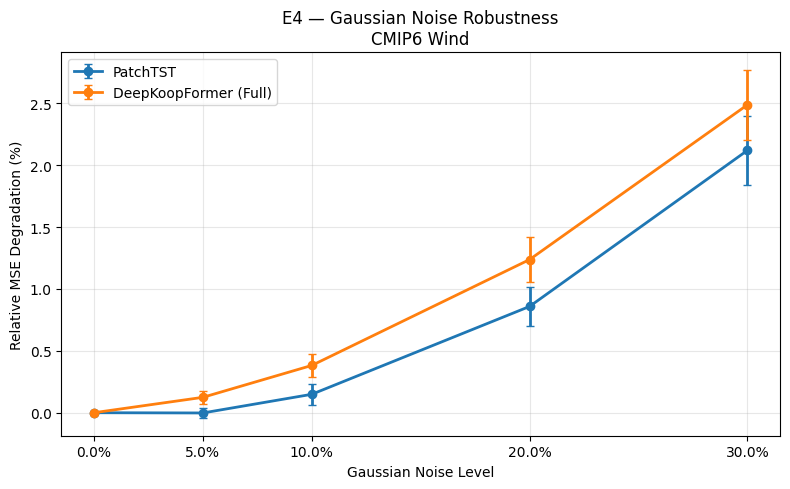

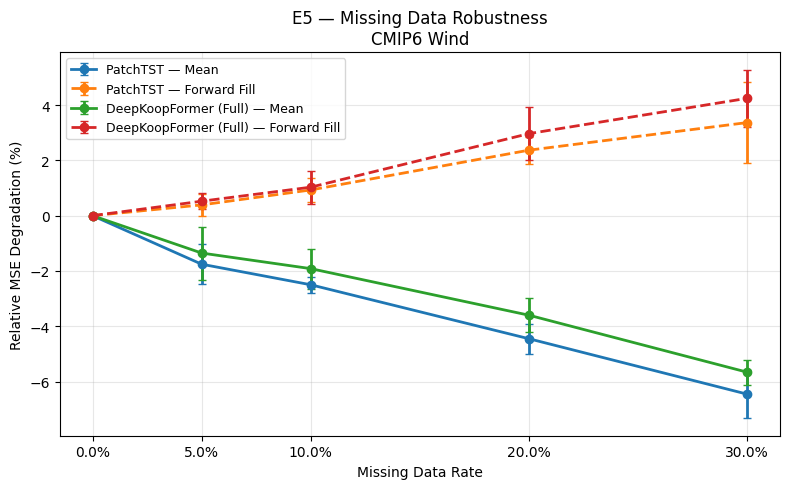

Saved 6 figures for CMIP6 Wind

=== VISUALIZATION COMPLETE ===
Saved: electricity_noise_mse.png
Saved: electricity_missing_mse.png
Saved: electricity_noise_mae.png
Saved: electricity_missing_mae.png
Saved: electricity_noise_mse_degradation_pct.png
Saved: electricity_missing_mse_degradation_pct.png
Saved: cmip6_wind_noise_mse.png
Saved: cmip6_wind_missing_mse.png
Saved: cmip6_wind_noise_mae.png
Saved: cmip6_wind_missing_mae.png
Saved: cmip6_wind_noise_mse_degradation_pct.png
Saved: cmip6_wind_missing_mse_degradation_pct.png

Total figures: 12
E4 evaluations: 100
E5 evaluations: 200
Output directory: c:\Users\Win 11 New\Desktop\pa gk\experiments\07_real_world_robustness\results\noise_missing\figures

E4 & E5 VISUALIZATION PASSED!


In [6]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import pandas as pd
import numpy as np

# 1. Load saved evaluation results
noise_df = pd.read_csv(
    RESULTS_DIR / "noise_metrics.csv"
)

missing_df = pd.read_csv(
    RESULTS_DIR / "missing_metrics.csv"
)

FIG_DIR = RESULTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

assert len(noise_df) == 100, "E4 results incomplete"
assert len(missing_df) == 200, "E5 results incomplete"

METRICS = {
    "MSE": "Test MSE (Original Scale)",
    "MAE": "Test MAE (Original Scale)",
    "MSE_Degradation_Pct": "Relative MSE Degradation (%)"
}

DATASET_SLUGS = {
    "Electricity": "electricity",
    "CMIP6 Wind": "cmip6_wind"
}

MODEL_LABELS = {
    "PatchTST": "PatchTST",
    "KoopPatchTST_Full": "DeepKoopFormer (Full)"
}

METHOD_LABELS = {
    "mean": "Mean",
    "forward_fill": "Forward Fill"
}

saved_figures = []


# 2. Utility: calculate mean and standard deviation
def aggregate_metric(df, group_cols, metric):
    return (
        df.groupby(group_cols, as_index=False)
        .agg(
            Mean=(metric, "mean"),
            Std=(metric, "std")
        )
        .fillna({"Std": 0.0})
    )


# 3. E4 — Noise Robustness
def plot_noise(dataset_name, metric):

    subset = noise_df[
        noise_df["Dataset"] == dataset_name
    ]

    agg = aggregate_metric(
        subset,
        ["Model", "Noise_Level"],
        metric
    )

    fig, ax = plt.subplots(figsize=(8, 5))

    for model_name in MODEL_NAMES:

        data = agg[
            agg["Model"] == model_name
        ].sort_values("Noise_Level")

        assert len(data) == len(NOISE_LEVELS)

        ax.errorbar(
            data["Noise_Level"],
            data["Mean"],
            yerr=data["Std"],
            marker="o",
            linewidth=2,
            capsize=3,
            label=MODEL_LABELS[model_name]
        )

    ax.set_title(
        f"E4 — Gaussian Noise Robustness\n{dataset_name}"
    )
    ax.set_xlabel("Gaussian Noise Level")
    ax.set_ylabel(METRICS[metric])

    ax.set_xticks(NOISE_LEVELS)
    ax.xaxis.set_major_formatter(
        PercentFormatter(xmax=1.0)
    )

    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()

    filename = (
        f"{DATASET_SLUGS[dataset_name]}"
        f"_noise_{metric.lower()}.png"
    )

    path = FIG_DIR / filename
    fig.savefig(path, dpi=300, bbox_inches="tight")

    saved_figures.append(path)

    plt.show()
    plt.close(fig)


# 4. E5 — Missing Data Robustness
def plot_missing(dataset_name, metric):

    subset = missing_df[
        missing_df["Dataset"] == dataset_name
    ]

    agg = aggregate_metric(
        subset,
        ["Model", "Imputation", "Missing_Rate"],
        metric
    )

    fig, ax = plt.subplots(figsize=(8, 5))

    LINE_STYLES = {
        "mean": "-",
        "forward_fill": "--"
    }

    for model_name in MODEL_NAMES:

        for method in IMPUTATION_METHODS:

            data = agg[
                (agg["Model"] == model_name)
                & (agg["Imputation"] == method)
            ].sort_values("Missing_Rate")

            assert len(data) == len(MISSING_RATES)

            label = (
                f"{MODEL_LABELS[model_name]} "
                f"— {METHOD_LABELS[method]}"
            )

            ax.errorbar(
                data["Missing_Rate"],
                data["Mean"],
                yerr=data["Std"],
                marker="o",
                linestyle=LINE_STYLES[method],
                linewidth=2,
                capsize=3,
                label=label
            )

    ax.set_title(
        f"E5 — Missing Data Robustness\n{dataset_name}"
    )
    ax.set_xlabel("Missing Data Rate")
    ax.set_ylabel(METRICS[metric])

    ax.set_xticks(MISSING_RATES)
    ax.xaxis.set_major_formatter(
        PercentFormatter(xmax=1.0)
    )

    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)
    fig.tight_layout()

    filename = (
        f"{DATASET_SLUGS[dataset_name]}"
        f"_missing_{metric.lower()}.png"
    )

    path = FIG_DIR / filename
    fig.savefig(path, dpi=300, bbox_inches="tight")

    saved_figures.append(path)

    plt.show()
    plt.close(fig)


# 5. Generate all figures
print("=== E4 & E5 VISUALIZATION ===")

for dataset_name in DATASET_FILES:

    print(f"\nDATASET: {dataset_name}")

    for metric in METRICS:

        plot_noise(dataset_name, metric)
        plot_missing(dataset_name, metric)

    print(f"Saved 6 figures for {dataset_name}")


# 6. Final verification
assert len(saved_figures) == 12
assert all(path.is_file() for path in saved_figures)

print("\n=== VISUALIZATION COMPLETE ===")

for path in saved_figures:
    print("Saved:", path.name)

print("\nTotal figures:", len(saved_figures))
print("E4 evaluations:", len(noise_df))
print("E5 evaluations:", len(missing_df))
print("Output directory:", FIG_DIR)

print("\nE4 & E5 VISUALIZATION PASSED!")
